![Banner](../images/03_05_banner_spatial_analysis_Network.png)



# Geographic Embedding of Nodes and Edges



## Overview

A **spatial network** is a network whose nodes and edges are *embedded in geographic
space*. Every node has coordinates, and edges usually have a physical form (road, pipe,
river) or a cost that depends on distance (travel time, shipping cost, likelihood of a
social tie).

This notebook uses `geolattice.spatial_analysis.network_analysis` with the synthetic road
network in `Data/00_shared/data_spatial_net/` to cover:

- Node coordinates and CRS (lon/lat vs projected)
- Edge lengths with **haversine** vs projected Euclidean distance
- Graph ↔ GeoDataFrame conversion (OSMnx / NetworkX)
- Spatial descriptors: circuity, Kansky α/β/γ, planarity
- Spatially embedded random graphs (RGG, Waxman) and link-probability vs distance



## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`data/data_spatial_net`, and imports `geolattice.spatial_analysis.network_analysis` as `sna`.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / network / plotting stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O and CRS transforms
import matplotlib.pyplot as plt  # figure and axes creation for maps
import networkx as nx  # graph construction and shortest paths
import numpy as np  # array ops for distances and random samples
import pandas as pd  # tabular display of edge lengths and indices
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # hide library warnings in notebook output

# ===================================================================
# Setup for geographic embedding demos.
# Import GeoLattice, point DATA at Data/00_shared/data_spatial_net,
# and import network_analysis as sna.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Synthetic road / town data used by the network chapter.
DATA = ROOT / "Data" / "00_shared" / "data_spatial_net"  # chapter sample-data folder under the repo

# Spatial network helpers (haversine, Kansky indices, graph loaders).
from geolattice.spatial_analysis import network_analysis as sna  # spatial network helpers aliased as sna

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # compact figures with cleaner spines
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}  # notebook step
)
# Confirm which folders and library versions the notebook will use.
print("repo:", ROOT)  # status line for the notebook reader
print("data:", DATA)  # status line for the notebook reader
print("networkx", nx.__version__, "| geopandas", gpd.__version__)  # status line for the notebook reader

# OSMnx bridges NetworkX graphs and GeoDataFrames; Shapely builds geometries.
import osmnx as ox  # graph_to_gdfs and network statistics
from shapely.geometry import Point, LineString  # point/line constructors (available for later cells)



repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/00_shared/data_spatial_net
networkx 3.6.1 | geopandas 1.1.4


## Part A: Nodes with coordinates

In NetworkX a node can carry any attribute. For a spatial network the essential ones are its coordinates and the CRS those coordinates are in. We start with a small network of New York cities in **longitude/latitude (EPSG:4326)**.



In [2]:
# ===================================================================
# Build a small New York city graph in lon/lat (EPSG:4326).
# Nodes store OSMnx-style x/y attributes; edges are unweighted until
# haversine lengths are attached in the next code cell.
# ===================================================================

# City names with longitude (x) and latitude (y) in WGS 84.
cities = pd.DataFrame({  # city names with lon/lat in WGS 84
    "city": ["Ithaca", "Syracuse", "Rochester", "Buffalo", "Albany", "Binghamton", "Elmira", "New York"],  # continue string literal
    "lon":  [-76.50, -76.15, -77.61, -78.88, -73.76, -75.92, -76.81, -74.01],  # degrees east
    "lat":  [ 42.44,  43.05,  43.16,  42.89,  42.65,  42.10,  42.09,  40.71],  # degrees north
})
# Undirected city-to-city links that define the toy transport graph.
links = [("Ithaca", "Syracuse"), ("Ithaca", "Binghamton"), ("Ithaca", "Elmira"),  # undirected city-to-city edges
         ("Ithaca", "Rochester"), ("Syracuse", "Rochester"), ("Rochester", "Buffalo"),  # continue multi-line call
         ("Syracuse", "Albany"), ("Binghamton", "Elmira"), ("Binghamton", "New York"),  # continue multi-line call
         ("Albany", "New York")]  # run this analysis or plotting step

# Empty undirected graph tagged with the geographic CRS of the coordinates.
G_ny = nx.Graph(crs="EPSG:4326")  # small New York city toy graph
# Add one node per city with OSMnx convention: x = lon, y = lat.
for r in cities.itertuples():  # iterate GeoDataFrame rows as named tuples
    G_ny.add_node(r.city, x=r.lon, y=r.lat)  # OSMnx convention: x = lon/easting, y = lat/northing
# Add the undirected edges listed above.
G_ny.add_edges_from(links)  # add graph elements
# Summarise the graph and inspect Ithaca's node attributes.
print(G_ny)  # status line for the notebook reader
G_ny.nodes["Ithaca"]  # notebook step



Graph with 8 nodes and 10 edges


{'x': -76.5, 'y': 42.44}

### Edge lengths: never use Euclidean distance on degrees

One degree of longitude in New York is about 82 km, but one degree of latitude is about 111 km. Treating lon/lat as flat x/y therefore distorts distances. Two correct options:

1. **Haversine (great-circle)** distance directly on lon/lat.
2. **Project** to a metric CRS (e.g., UTM 18N) and use Euclidean distance.



In [3]:
# ===================================================================
# Compare haversine, UTM Euclidean, and a naive degree*111 km shortcut.
# Haversine and UTM should agree; the naive shortcut overstates E-W spans.
# ===================================================================

# Edge lengths with geolattice.spatial_analysis.network_analysis.haversine_km.
# Project city points to UTM 18N for a metric Euclidean comparison.
pts = gpd.GeoSeries(gpd.points_from_xy(cities.lon, cities.lat), crs="EPSG:4326").to_crs("EPSG:32618")  # projected city points for Euclidean km
proj = dict(zip(cities.city, pts))  # city name -> projected Point

rows = []  # accumulate one length comparison per edge
for u, v in G_ny.edges:  # iterate over the collection
    a, b = G_ny.nodes[u], G_ny.nodes[v]  # node attribute dicts with x/y
    hav = sna.haversine_km(a["x"], a["y"], b["x"], b["y"])  # great-circle km on lon/lat
    naive = np.hypot(a["x"] - b["x"], a["y"] - b["y"]) * 111.32  # degrees x 111 km shortcut
    utm = proj[u].distance(proj[v]) / 1000  # Euclidean km in UTM 18N
    G_ny.edges[u, v]["length_km"] = hav  # store haversine length on the edge
    rows.append({"edge": f"{u}-{v}", "haversine_km": hav, "utm_km": utm, "naive_deg_km": naive})  # append this record

# Round lengths for display and report the naive method's percent error.
dist = pd.DataFrame(rows).round(1)  # haversine vs UTM vs naive length table
dist["naive_error_%"] = ((dist.naive_deg_km - dist.haversine_km) / dist.haversine_km * 100).round(1)  # run this analysis or plotting step
dist  # notebook step



,edge,haversine_km,utm_km,naive_deg_km,naive_error_%
0,Ithaca-Syracuse,73.6,73.6,78.3,6.4
1,Ithaca-Binghamton,60.9,60.9,74.8,22.8
2,Ithaca-Elmira,46.5,46.5,52.0,11.8
3,Ithaca-Rochester,120.9,121.0,147.3,21.8
4,Syracuse-Rochester,119.2,119.5,163.0,36.7
5,Syracuse-Albany,199.8,200.3,269.8,35.0
6,Rochester-Buffalo,107.5,107.8,144.5,34.4
7,Albany-New York,216.7,216.4,217.7,0.5
8,Binghamton-Elmira,73.4,73.6,99.1,35.0
9,Binghamton-New York,221.9,222.0,263.0,18.5


Haversine and UTM agree within a fraction of a percent, while the naive degree shortcut overstates east-west distances by up to about 35%. Any shortest-path or accessibility result built on naive distances would be biased in a direction-dependent way.

### Drawing a graph in its true geographic position

`nx.draw` accepts a `pos` dictionary. Passing coordinates turns an abstract layout into a map.



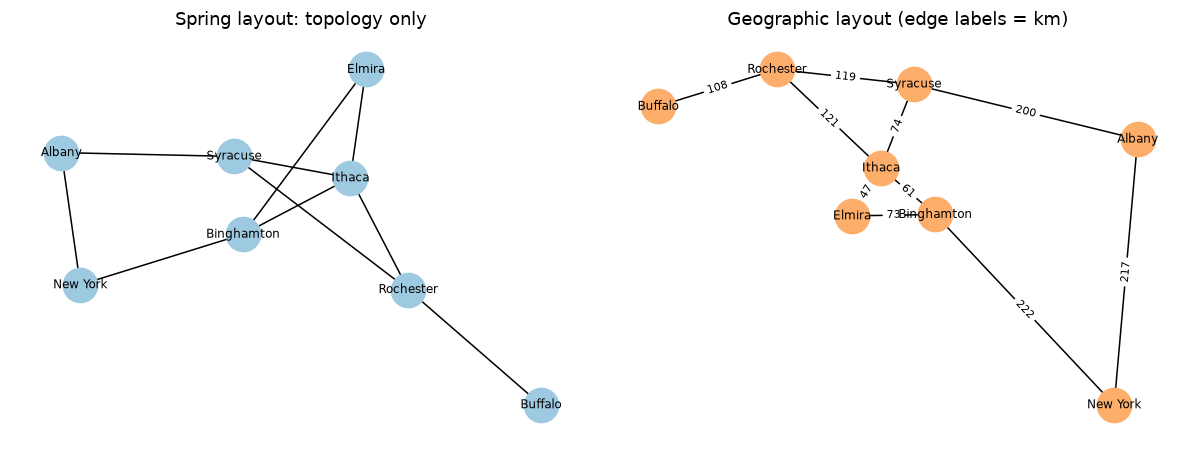

In [4]:
# ===================================================================
# Draw the same NY city graph twice: spring layout vs geographic layout.
# Geographic edge labels show haversine lengths in km.
# ===================================================================

# Position dictionary for a map-like layout using lon/lat as plot coordinates.
pos = {n: (d["x"], d["y"]) for n, d in G_ny.nodes(data=True)}  # node -> (x, y) layout dictionary
# Side-by-side axes: topology-only layout vs geographic layout.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))  # create a grid of subplot axes
# Left: force-directed spring layout (ignores geography).
nx.draw(  # draw the NetworkX graph
    G_ny,  # notebook step
    nx.spring_layout(G_ny, seed=3),  # reproducible abstract layout
    ax=axes[0],  # draw into these axes
    with_labels=True,  # print city names on nodes
    node_color="#9ecae1",  # NetworkX node colour
    node_size=500,  # hide or size junction markers
    font_size=8,  # label font size
)
axes[0].set_title("Spring layout: topology only")  # configure this subplot's labels or title
# Right: nodes placed at true lon/lat with km labels on edges.
nx.draw(  # draw the NetworkX graph
    G_ny,  # notebook step
    pos,  # geographic positions
    ax=axes[1],  # draw into these axes
    with_labels=True,  # print node labels on the graph
    node_color="#fdae6b",  # NetworkX node colour
    node_size=500,  # hide or size junction markers
    font_size=8,  # label font size
)
nx.draw_networkx_edge_labels(  # draw the NetworkX graph
    G_ny,  # notebook step
    pos,  # notebook step
    ax=axes[1],  # draw into these axes
    font_size=7,  # label font size
    edge_labels={(u, v): f"{d['length_km']:.0f}" for u, v, d in G_ny.edges(data=True)},  # km labels
)
axes[1].set_title("Geographic layout (edge labels = km)")  # configure this subplot's labels or title
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render both layouts



Same graph, two very different stories. The spring layout puts Ithaca in the middle because it has the highest degree; the geographic layout shows how stretched the Binghamton-New York connection really is.

Weighted shortest paths now respect real distances. An unweighted search cannot tell two equally short (in hops) routes apart:



In [5]:
# ===================================================================
# Elmira -> Albany: hop-count ties vs distance-weighted shortest path.
# Unweighted search cannot separate two equally short (in hops) routes.
# ===================================================================

# Print every unweighted shortest path and its total haversine length.
for p in nx.all_shortest_paths(G_ny, "Elmira", "Albany"):  # iterate over the collection
    hops = len(p) - 1  # number of edges on the path
    km = nx.path_weight(G_ny, p, "length_km")  # sum of haversine edge lengths
    print(f"{hops} hops: {' -> '.join(p):45s} {km:5.0f} km")  # status line for the notebook reader
# Distance-weighted shortest path (minimises length_km).
best = nx.shortest_path(G_ny, "Elmira", "Albany", weight="length_km")  # strategy with highest late-period adoption
print("Shortest by km:", " -> ".join(best))  # status line for the notebook reader



3 hops: Elmira -> Ithaca -> Syracuse -> Albany          320 km
3 hops: Elmira -> Binghamton -> New York -> Albany      512 km
Shortest by km: Elmira -> Ithaca -> Syracuse -> Albany


## Part B: Edges with geometry: graphs ↔ GeoDataFrames

Real infrastructure edges are not straight lines. Each edge should carry a **LineString** whose length is the true travel distance. OSMnx standardises this representation:

- a `MultiDiGraph` (directed, parallel edges allowed because two roads can join the same pair of intersections; one-way streets need direction),
- node attributes `x`, `y`, graph attribute `crs`,
- edge attributes `length` and `geometry`.

Our synthetic road network follows that convention, so every OSMnx function works on it exactly as on a downloaded OpenStreetMap network.



In [6]:
# ===================================================================
# Load the synthetic OSMnx-style road MultiDiGraph and convert to gdfs.
# Nodes are Points; edges are LineStrings indexed by (u, v, key).
# ===================================================================

# Read the offline GraphML road network from the chapter data folder.
G = sna.load_road_graph(DATA / "roads.graphml")  # load the offline OSMnx-style road MultiDiGraph
print(G)  # node/edge counts and graph type
print("CRS:", G.graph["crs"])  # projected CRS stored on the graph
# Convert the MultiDiGraph into node and edge GeoDataFrames.
nodes, edges = ox.graph_to_gdfs(G)  # convert MultiDiGraph to node/edge GeoDataFrames
display(nodes.head(3))  # point geometries and node attributes
display(edges[["highway", "maxspeed", "length", "geometry"]].head(3))  # key edge fields



MultiDiGraph with 439 nodes and 1416 edges
CRS: EPSG:32618


,x,y,street_count,geometry
osmid,,,,
1,370000.000000,4.692000e+06,1,POINT (370000 4692000)
22,372122.056854,4.691607e+06,4,POINT (372122.057 4691607.312)
21,372000.000000,4.690000e+06,2,POINT (372000 4690000)


highway maxspeed       length  \
u  v  key                                      
1  22 0    residential       50  2183.602022   
22 1  0    residential       50  2183.602022   
   21 0    residential       50  1616.030034   

                                                    geometry  
u  v  key                                                     
1  22 0    LINESTRING (370000 4692000, 371091.311 4691967...  
22 1  0    LINESTRING (372122.057 4691607.312, 371091.311...  
   21 0    LINESTRING (372122.057 4691607.312, 372118.313...

`graph_to_gdfs` gives two GeoDataFrames: nodes (Points) and edges (LineStrings, indexed by `u, v, key`). Now the full GeoPandas toolbox applies: spatial joins, buffers, overlays, plotting. `ox.graph_from_gdfs` goes the other way, which is exactly how `make_data.py` built this graph.



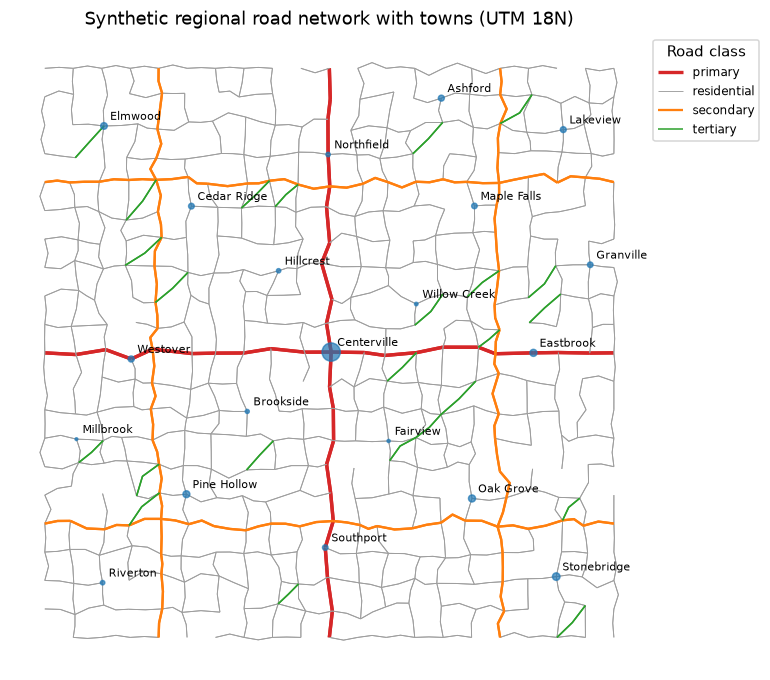

In [7]:
# ===================================================================
# Map the synthetic road network by highway class with town markers.
# Marker size scales with town population.
# ===================================================================

# Town points used as routing places in later notebooks.
towns = gpd.read_file(DATA / "towns.geojson")  # town points used as routing / flow places
# Colour and line width by OSM-like highway class.
colors = {"primary": "#d62728", "secondary": "#ff7f0e", "tertiary": "#2ca02c", "residential": "#9e9e9e"}  # colour sequence for mapped classes / budgets
widths = {"primary": 2.2, "secondary": 1.5, "tertiary": 1.0, "residential": 0.6}  # line widths by highway class

fig, ax = plt.subplots(figsize=(7.5, 7.5))  # create figure and primary axes
# Plot each highway class as its own layer so the legend lists classes.
for h, sub in edges.groupby("highway"):  # iterate over the collection
    sub.plot(ax=ax, color=colors[h], linewidth=widths[h], label=h)  # draw geometries or a series on the axes
# Town markers: area proportional to population.
towns.plot(ax=ax, markersize=towns.population / 600, color="#1f77b4", alpha=0.7, zorder=3)  # draw geometries or a series on the axes
# Label each town near its point geometry.
for r in towns.itertuples():  # iterate GeoDataFrame rows as named tuples
    ax.annotate(  # label a feature near its coordinates
        r.town,  # notebook step
        (r.geometry.x, r.geometry.y),  # continue multi-line call
        fontsize=7,  # font size
        xytext=(4, 4),  # annotation text offset in points
        textcoords="offset points",  # offset coordinate system for annotations
    )
ax.legend(title="Road class", loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)  # add a legend for mapped layers
ax.set_title("Synthetic regional road network with towns (UTM 18N)")  # panel / map title
ax.set_axis_off()  # hide coordinate ticks on the map
plt.show()  # render the figure in the notebook



## Part C: Describing a spatial network

### C1. Edge length and degree

Physical networks have **bounded degree**: you cannot fit 50 roads into one intersection. Compare this with the heavy-tailed degree distributions of social or web networks from Module 4.



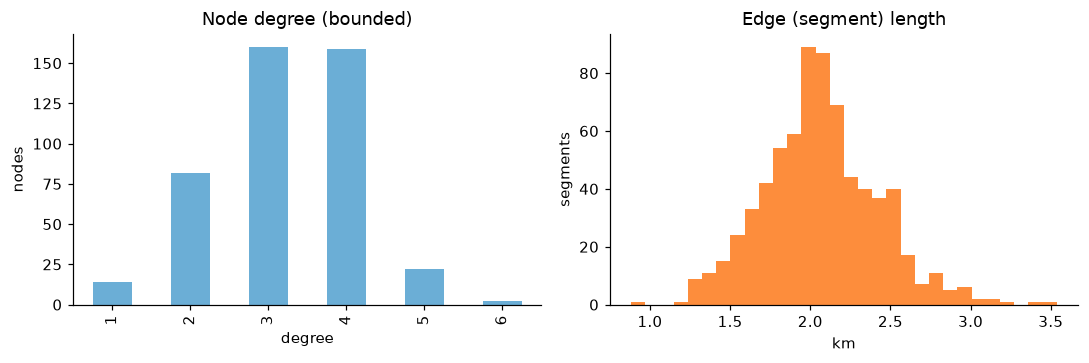

mean degree 3.23, max degree 6, mean segment 2.07 km


In [8]:
# ===================================================================
# Degree distribution and segment-length histogram for the road graph.
# Physical networks have bounded degree unlike many social graphs.
# ===================================================================

# Undirected view: one edge per road segment for descriptive stats.
Gu = ox.convert.to_undirected(G)  # undirected view for descriptive statistics
deg = pd.Series(dict(Gu.degree()))  # degree of every node
lengths = pd.Series([d["length"] for _, _, d in Gu.edges(data=True)])  # segment lengths (m)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))  # create a grid of subplot axes
# Left: how many nodes have each degree (bounded for street junctions).
deg.value_counts().sort_index().plot.bar(ax=axes[0], color="#6baed6")  # run this analysis or plotting step
axes[0].set(title="Node degree (bounded)", xlabel="degree", ylabel="nodes")  # configure this subplot's labels or title
# Right: distribution of individual road-segment lengths in km.
axes[1].hist(lengths / 1000, bins=30, color="#fd8d3c")  # run this analysis or plotting step
axes[1].set(title="Edge (segment) length", xlabel="km", ylabel="segments")  # configure this subplot's labels or title
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook
# Print a one-line summary of degree and mean segment length.
print(f"mean degree {deg.mean():.2f}, max degree {deg.max()}, mean segment {lengths.mean()/1000:.2f} km")  # status line for the notebook reader



### C2. Circuity (detour index)

**Circuity** = network distance ÷ straight-line distance. A value of 1.0 means a perfectly direct route; values of 1.2-1.4 are typical of real road networks. High circuity flags places where the network forces long detours (rivers without bridges, sparse rural grids).



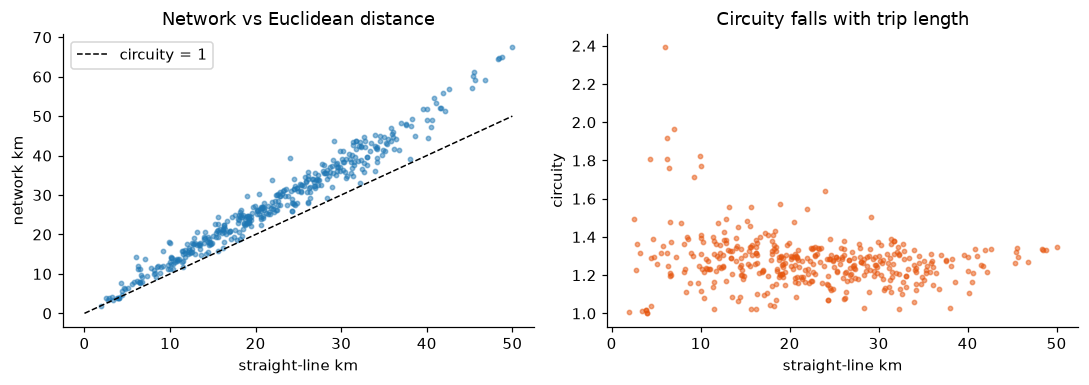

median circuity 1.266; OSMnx network-wide average: 1.016


In [9]:
# ===================================================================
# Sample OD pairs and compare network distance with Euclidean distance.
# Circuity = network_km / euclid_km; median should sit around 1.2-1.4.
# ===================================================================

# Reproducible RNG for sampling origin-destination node pairs.
rng = np.random.default_rng(1)  # reproducible random generator
node_ids = np.array(list(G.nodes))  # all junction ids as an array
pairs = rng.choice(node_ids, size=(400, 2))  # 400 random (o, d) draws
recs = []  # accumulate distance pairs for the scatter plots
for o, d in pairs:  # iterate over the collection
    if o == d:  # conditional branch
        continue  # skip degenerate same-node pairs
    # Shortest-path length along the road network (metres).
    network_len = nx.shortest_path_length(G, o, d, weight="length")  # network_len argument
    # Straight-line Euclidean distance in the projected CRS (metres).
    euc = np.hypot(G.nodes[o]["x"] - G.nodes[d]["x"], G.nodes[o]["y"] - G.nodes[d]["y"])  # euc argument
    recs.append({"euclid_km": euc / 1000, "network_km": network_len / 1000})  # append this record
circ = pd.DataFrame(recs)  # route circuity records
circ["circuity"] = circ.network_km / circ.euclid_km  # route detour index

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))  # create a grid of subplot axes
# Left: network km vs straight-line km (dashed line = circuity 1).
axes[0].scatter(circ.euclid_km, circ.network_km, s=8, alpha=0.5)  # scatter points on the axes
m = circ.euclid_km.max()  # axis limit for the 1:1 reference line
axes[0].plot([0, m], [0, m], "k--", lw=1, label="circuity = 1")  # draw geometries or a series on the axes
axes[0].set(xlabel="straight-line km", ylabel="network km", title="Network vs Euclidean distance")  # configure this subplot's labels or title
axes[0].legend()  # add a legend
# Right: circuity against trip length (short trips are more circuitous).
axes[1].scatter(circ.euclid_km, circ.circuity, s=8, alpha=0.5, color="#e6550d")  # scatter points on the axes
axes[1].set(xlabel="straight-line km", ylabel="circuity", title="Circuity falls with trip length")  # configure this subplot's labels or title
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook
# Compare our route-level median with OSMnx edge-level circuity_avg.
print(  # status line for the notebook reader
    f"median circuity {circ.circuity.median():.3f}; OSMnx network-wide average: "  # run this analysis or plotting step
    f"{ox.stats.circuity_avg(Gu):.3f}"  # run this analysis or plotting step
)



Note the two numbers measure different things. Our **route circuity** compares origin-destination trips; OSMnx's `circuity_avg` is **edge circuity**, the average bend of individual road segments (curved length ÷ chord length). Both are useful: edge circuity describes road geometry, route circuity describes how well the network connects places.

Short trips are the most circuitous because a single detour is large relative to the trip; long trips average out. This is a general property of grid-like networks and an important caveat when people use straight-line distance as a proxy for access (Section 03.06.4).

### C3. Connectivity indices from transport geography

Three classic indices (Kansky, 1963) summarise how well-connected a planar network is, using $v$ nodes, $e$ edges and $p$ connected components:

- **Beta** $\beta = e / v$: edges per node. Trees have $\beta < 1$; meshed grids approach 2.
- **Alpha (meshedness)** $\alpha = (e - v + p) / (2v - 5)$: share of the maximum possible independent cycles in a planar graph (0 = tree, 1 = maximally meshed).
- **Gamma** $\gamma = e / [3(v - 2)]$: share of the maximum possible edges in a planar graph.



In [10]:
# ===================================================================
# Kansky alpha / beta / gamma for the roads, a spanning tree, and a grid.
# The road network should sit between a tree and a perfect grid.
# ===================================================================

# Simple undirected graph required by the classic planar indices.
Gs = nx.Graph(Gu)  # simple undirected graph for planar indices
# Length-minimising spanning tree (no cycles; alpha near 0).
tree = nx.minimum_spanning_tree(Gs, weight="length")  # minimum spanning tree reference graph
# Dense planar reference: a 21x21 lattice.
full_grid = nx.grid_2d_graph(21, 21)  # dense planar grid for index comparison
# Side-by-side Kansky indices for the three graphs.
idx = pd.DataFrame({  # Kansky indices side-by-side
    "our road network": sna.kansky_indices(Gs),  # call a geolattice.network_analysis helper
    "its spanning tree": sna.kansky_indices(tree),  # call a geolattice.network_analysis helper
    "complete 21x21 grid": sna.kansky_indices(full_grid),  # call a geolattice.network_analysis helper
}).T.round(3)  # run this analysis or plotting step
idx  # notebook step



,nodes,edges,beta,alpha,gamma
our road network,439.0,708.0,1.613,0.309,0.540
its spanning tree,439.0,438.0,0.998,0.000,0.334
complete 21x21 grid,441.0,840.0,1.905,0.456,0.638


The road network sits between a tree (no redundancy at all) and a perfect grid. Removing about a fifth of local roads in the generator lowered meshedness, which means fewer alternative routes when a road is closed (Module 6 robustness ideas apply directly here).

### C4. Planarity

A graph is **planar** if it can be drawn without edges crossing. Street networks are close to planar, but bridges and overpasses break planarity in real data, so planarity is a useful sanity check rather than a guarantee.



In [11]:
# ===================================================================
# Planarity sanity checks on the road graph, city graph, and K5.
# Street networks are nearly planar; K5 is the classic non-planar case.
# ===================================================================

print("Road network planar?   ", nx.is_planar(Gs))  # synthetic roads should be planar
print("NY city network planar?", nx.is_planar(G_ny))  # small city graph is planar
print("K5 (complete, 5 nodes)?", nx.is_planar(nx.complete_graph(5)))  # K5 is not planar



Road network planar?    True
NY city network planar? True
K5 (complete, 5 nodes)? False


## Part D: Spatially embedded random graphs

Generative models from Module 8 ignore space. Two classic models add it:

- **Random geometric graph (RGG):** connect two nodes if they are within radius $r$. Hard distance threshold.
- **Waxman graph:** connect with probability $p(d) = \beta\, e^{-d / (\alpha L)}$, where $L$ is the maximum distance. Soft distance decay, allows occasional long links.

These are the null models for any relational network embedded in space, including the farmer advice network in 03.06.6.



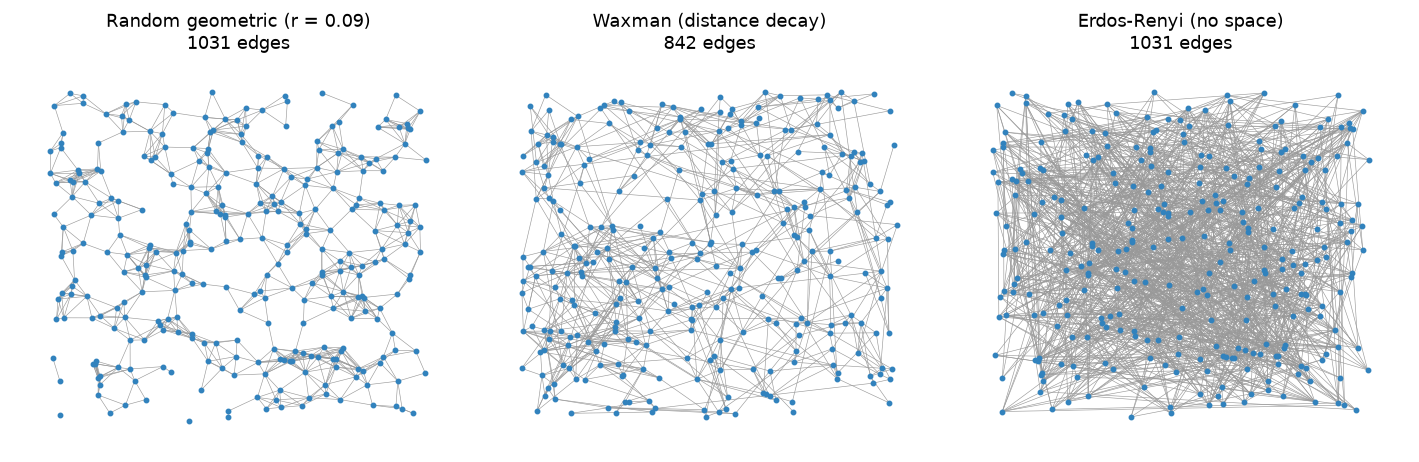

In [12]:
# ===================================================================
# Compare RGG, Waxman, and Erdos-Renyi embeddings with the same n.
# RGG uses a hard radius; Waxman soft distance decay; ER ignores space.
# ===================================================================

n = 300  # number of random nodes in the unit square
# Random positions shared by RGG and the ER comparison layout.
pos_rand = {i: tuple(p) for i, p in enumerate(np.random.default_rng(7).random((n, 2)))}  # random unit-square node positions
# Hard threshold: link nodes within radius 0.09.
rgg = nx.random_geometric_graph(n, radius=0.09, pos=pos_rand, seed=7)  # random geometric graph
# Soft decay: occasional long links allowed by the Waxman model.
wax = nx.waxman_graph(n, beta=0.6, alpha=0.06, domain=(0, 0, 1, 1), seed=7)  # Waxman distance-decay graph
wpos = nx.get_node_attributes(wax, "pos")  # Waxman stores its own positions
# Erdos-Renyi with the same edge count as the RGG (no spatial rule).
er = nx.gnm_random_graph(n, rgg.number_of_edges(), seed=7)  # Erdos-Renyi graph with matched edge count

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))  # create a grid of subplot axes
# Draw each generative model in geographic (or assigned) position.
for ax, g, p, title in [  # notebook step
    (axes[0], rgg, pos_rand, "Random geometric (r = 0.09)"),  # continue multi-line call
    (axes[1], wax, wpos, "Waxman (distance decay)"),  # continue multi-line call
    (axes[2], er, pos_rand, "Erdos-Renyi (no space)"),  # continue multi-line call
]:
    nx.draw(g, p, ax=ax, node_size=8, width=0.4, node_color="#3182bd", edge_color="#999")  # draw the NetworkX graph
    ax.set_title(f"{title}\n{g.number_of_edges()} edges")  # panel / map title
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook



In [13]:
# ===================================================================
# Component summary for RGG, Waxman, and Erdos-Renyi (same edge budget).
# Expect higher clustering and longer paths under hard spatial thresholds.
# ===================================================================

pd.DataFrame({  # run this analysis or plotting step
    "RGG": sna.graph_component_summary(rgg),  # call a geolattice.network_analysis helper
    "Waxman": sna.graph_component_summary(wax),  # call a geolattice.network_analysis helper
    "Erdos-Renyi": sna.graph_component_summary(er),  # call a geolattice.network_analysis helper
}).T.round(3)  # run this analysis or plotting step



,edges,avg clustering,largest component %,avg path length (LCC)
RGG,1031.0,0.589,98.667,8.395
Waxman,842.0,0.094,99.333,4.168
Erdos-Renyi,1031.0,0.025,100.000,3.173


**Key lesson.** A hard distance threshold (RGG) produces **high clustering** (your neighbours are close to each other, so they are also neighbours) and **long path lengths** (you can only hop a short distance at a time). The Erdős-Rényi graph with a similar number of edges has almost no clustering but short paths. The Waxman model's few long links shorten paths, the same "small-world" effect we will exploit when seeding technology diffusion in 03.06.6.

### Distance decay of link probability

Plotting the share of node pairs that are linked at each distance band reveals the **distance-decay function**, the signature of any spatial network.



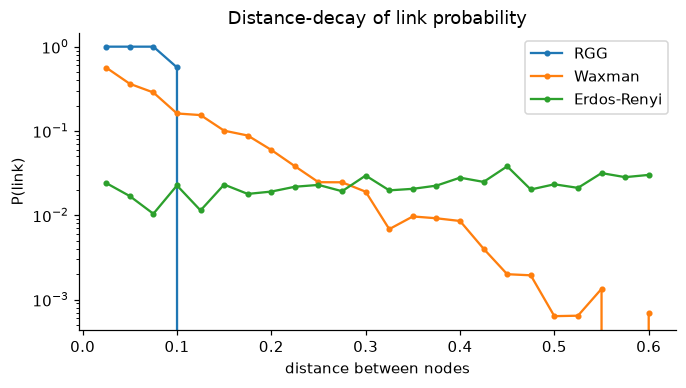

In [14]:
# ===================================================================
# Distance-decay curves: P(link) vs separation for each generative model.
# RGG drops at the radius; Waxman decays smoothly; ER is roughly flat.
# ===================================================================

bins = np.linspace(0, 0.6, 25)  # distance bands for the empirical P(link)
fig, ax = plt.subplots(figsize=(7, 3.5))  # create figure and primary axes
# Overlay link-probability curves for the three models.
for g, p, lab in [(rgg, pos_rand, "RGG"), (wax, wpos, "Waxman"), (er, pos_rand, "Erdos-Renyi")]:  # iterate over the collection
    sna.link_probability_by_distance(g, p, bins).plot(ax=ax, marker="o", ms=3, label=lab)  # draw geometries or a series on the axes
ax.set(  # set labels, title, or axis limits
    xlabel="distance between nodes",  # x-axis label
    ylabel="P(link)",  # y-axis label
    title="Distance-decay of link probability",  # plot or map title
    yscale="log",  # log scale highlights the decay shape
)
ax.legend()  # add a legend for mapped layers
plt.show()  # render the figure in the notebook



## Summary

Helpers used here live in `geolattice.spatial_analysis.network_analysis` (`haversine_km`, `kansky_indices`, `graph_component_summary`, `link_probability_by_distance`, `load_road_graph`). Tutorial data: `Data/00_shared/data_spatial_net/`.


- A spatial network = graph + coordinates + CRS + (often) edge geometries.
- Compute lengths with **haversine** on lon/lat or **project** first; never use raw degrees.
- OSMnx's `MultiDiGraph` + `graph_to_gdfs` / `graph_from_gdfs` is the standard bridge between NetworkX and GeoPandas.
- Spatial descriptors: bounded degree, **circuity**, **alpha/beta/gamma**, planarity, and the **distance-decay** curve.
- Spatial embedding → high clustering, long paths; a few long-range links create small-world shortcuts.

### Exercises

1. Add Plattsburgh (-73.45, 44.70) linked to Albany. How large is the naive-degree error on that north-south edge compared with east-west edges? Why?
2. Compute circuity separately for trips that start within 5 km of Centerville versus trips that start near the region's edge. Which area is better served?
3. Delete all `primary` edges and recompute the alpha index and median circuity. What does the highway contribute?
4. Vary the Waxman `alpha` parameter (0.02 → 0.3) and plot average path length against average clustering.

**Next:** 03.06.2 uses OSMnx for routing, travel times, and isochrones on this road network.

